# Reproducible Data Workflow: Wine Quality Analysis

**Author:** Alex Kuzmin  
**Dataset:** [Wine Quality — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality) (red and white *Vinho Verde* wines)

This project builds a complete, reproducible data workflow in Python: it loads the red and white Wine Quality datasets, cleans and combines them with reusable functions, explores the data, and visualizes how physicochemical properties relate to expert quality ratings. The goal is a clean, documented pipeline that later machine learning projects can build on.

## 1. Setup

Import the required libraries and set display options. A fixed random seed is defined so that any future step that uses randomness (for example sampling or a train/test split) produces the same result on every run.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display and plotting defaults
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")

# Fixed seed for reproducibility of any random operations
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"NumPy {np.__version__} | Pandas {pd.__version__} | Seaborn {sns.__version__}")

NumPy 2.5.4 | Pandas 3.1.1 | Seaborn 0.13.2


## 2. Data Ingestion

The dataset is published as two semicolon-separated CSV files, one for red wines and one for white wines. Both files are stored in the same folder as this notebook. Each file is loaded separately, labelled with a `wine_type` column, and then combined into a single DataFrame so that both wine types can be analysed together.

In [30]:
RED_PATH = "winequality-red.csv"
WHITE_PATH = "winequality-white.csv"

red = pd.read_csv(RED_PATH, sep=";")
white = pd.read_csv(WHITE_PATH, sep=";")

red["wine_type"] = "red"
white["wine_type"] = "white"

df = pd.concat([red, white], ignore_index=True)

print(f"Red wines:   {red.shape[0]:,} rows x {red.shape[1]} columns")
print(f"White wines: {white.shape[0]:,} rows x {white.shape[1]} columns")
print(f"Combined:    {df.shape[0]:,} rows x {df.shape[1]} columns")

Red wines:   1,599 rows x 13 columns
White wines: 4,898 rows x 13 columns
Combined:    6,497 rows x 13 columns


In [31]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,red


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [33]:
# Quick data-quality checks on the raw data (before cleaning)
print("Missing values per column:")
print(df.isna().sum().to_string())
print(f"\nExact duplicate rows: {df.duplicated().sum():,}")

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0

Exact duplicate rows: 1,177


**Initial observations.** The combined dataset has 6,497 rows (1,599 red and 4,898 white wines) and 13 columns: 11 numeric physicochemical measurements, the integer `quality` score, and the added `wine_type` label. No column contains missing values, so missing-data handling is not the main cleaning concern here. However, 1,177 rows (about 18% of the data) are exact duplicates of another row. Column names also contain spaces, which makes them awkward to use in code. Both issues are addressed in the Data Cleaning section.

## 3. Data Cleaning

The checks in the ingestion step showed two issues to fix: column names with spaces, and a large number of exact duplicate rows. Each cleaning step below is written as a reusable function with a docstring, so the same steps can be applied to new data in a later project. The functions are then chained into a single pipeline.

### 3.1 Standardize column names

In [34]:
def standardize_column_names(df):
    """Return a copy of the DataFrame with clean, code-friendly column names.

    Column names are stripped of surrounding whitespace, converted to
    lowercase, and have internal spaces replaced with underscores
    (for example, "fixed acidity" becomes "fixed_acidity").

    Parameters
    ----------
    df : pandas.DataFrame
        The input data.

    Returns
    -------
    pandas.DataFrame
        A copy of ``df`` with standardized column names. The input is not modified.
    """
    cleaned = df.copy()
    cleaned.columns = (
        cleaned.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
    )
    return cleaned

**Why this step is needed.** The original column names contain spaces and mixed case (for example `fixed acidity` and `pH`). These names cannot be used with attribute access (`df.fixed_acidity`), are easy to mistype, and often cause problems when the data is passed to other tools later. Converting every name to lowercase `snake_case` gives one consistent naming rule for the rest of the workflow.

### 3.2 Remove duplicate rows

In [35]:
def remove_duplicates(df, subset=None, verbose=True):
    """Return a copy of the DataFrame with exact duplicate rows removed.

    The first occurrence of each duplicated row is kept. When ``verbose`` is
    True, the number of rows before and after removal is printed so the
    effect of this step is visible and documented.

    Parameters
    ----------
    df : pandas.DataFrame
        The input data.
    subset : list of str, optional
        Columns to consider when identifying duplicates. Defaults to all columns.
    verbose : bool, default True
        Whether to print a short report of how many rows were removed.

    Returns
    -------
    pandas.DataFrame
        A copy of ``df`` without duplicate rows, with a fresh 0..n-1 index.
    """
    n_before = len(df)
    cleaned = df.drop_duplicates(subset=subset, keep="first").reset_index(drop=True)
    if verbose:
        n_removed = n_before - len(cleaned)
        print(f"remove_duplicates: {n_before:,} -> {len(cleaned):,} rows "
              f"({n_removed:,} removed, {n_removed / n_before:.1%})")
    return cleaned

**Why this step is needed.** The ingestion checks found 1,177 rows (18.1% of the data) that exactly repeat another row on all 13 columns: 240 in the red file and 937 in the white file. If they are kept, those wines count two or more times, which over-weights them in the summary statistics and correlations. In a future machine learning project, the same wine could also appear in both the training and test sets, which would make the model look better than it is. Only the first copy of each row is kept.

**Assumption.** The dataset has no wine ID column, so it is not possible to confirm whether a duplicate is a data-entry repeat or a different wine with identical measurements. With 11 measurements recorded to several decimal places, an exact match on every column is much more likely to be a repeated record, so removal is the safer choice. This assumption is revisited in the Summary section.

### 3.3 Handle missing values

In [36]:
def handle_missing_values(df, strategy="median", verbose=True):
    """Return a copy of the DataFrame with missing numeric values filled.

    Missing values in numeric columns are replaced with the column median
    (default) or mean. Rows with missing values in non-numeric columns are
    dropped, because there is no meaningful number to fill them with.

    Parameters
    ----------
    df : pandas.DataFrame
        The input data.
    strategy : {"median", "mean"}, default "median"
        Statistic used to fill missing numeric values.
    verbose : bool, default True
        Whether to print how many missing values were found and handled.

    Returns
    -------
    pandas.DataFrame
        A copy of ``df`` with no missing values.

    Raises
    ------
    ValueError
        If ``strategy`` is not "median" or "mean".
    """
    if strategy not in ("median", "mean"):
        raise ValueError("strategy must be 'median' or 'mean'")
    cleaned = df.copy()
    n_missing = int(cleaned.isna().sum().sum())
    numeric_cols = cleaned.select_dtypes(include="number").columns
    fill_values = getattr(cleaned[numeric_cols], strategy)()
    cleaned[numeric_cols] = cleaned[numeric_cols].fillna(fill_values)
    cleaned = cleaned.dropna().reset_index(drop=True)
    if verbose:
        print(f"handle_missing_values: {n_missing:,} missing values found "
              f"and handled using the {strategy}")
    return cleaned

**Why this step is needed.** The ingestion checks found no missing values in this dataset, and the function confirms that 0 values were changed. It is still included as a permanent safeguard, because a reusable workflow should not fail or silently produce wrong results if a future version of the data contains gaps. The median is the default fill value because several features are strongly right-skewed (for example `residual_sugar` and `chlorides`), and the median is much less affected by extreme values than the mean.

### 3.4 Flag outliers

In [37]:
def flag_outliers_iqr(df, columns, k=1.5, verbose=True):
    """Add a boolean column marking rows with an outlier in any given column.

    A value is an outlier if it lies more than ``k`` times the interquartile
    range (IQR) below the first quartile or above the third quartile. Rows are
    only flagged, not removed, so later analysis can decide how to treat them.

    Parameters
    ----------
    df : pandas.DataFrame
        The input data.
    columns : list of str
        Numeric columns to check for outliers.
    k : float, default 1.5
        IQR multiplier that sets how far from the quartiles a value must be.
    verbose : bool, default True
        Whether to print the number of outliers found per column.

    Returns
    -------
    pandas.DataFrame
        A copy of ``df`` with an added boolean column ``is_outlier``.
    """
    flagged = df.copy()
    is_outlier = pd.Series(False, index=flagged.index)
    counts = {}
    for col in columns:
        q1, q3 = flagged[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        col_mask = (flagged[col] < q1 - k * iqr) | (flagged[col] > q3 + k * iqr)
        counts[col] = int(col_mask.sum())
        is_outlier |= col_mask
    flagged["is_outlier"] = is_outlier
    if verbose:
        print("Outliers per column (IQR rule, k = %.1f):" % k)
        for col, n in counts.items():
            print(f"  {col:<22} {n:>5,}")
        print(f"Rows with at least one outlier: {int(is_outlier.sum()):,} "
              f"of {len(flagged):,} ({is_outlier.mean():.1%})")
    return flagged

**Why this step is needed.** Several features have extreme values, for example a white wine with 65.8 g/L of residual sugar when 75% of wines have 7.5 g/L or less. Outliers are **flagged rather than removed** for two reasons. First, the extreme values are plausible measurements (sweet wines really do contain more sugar), not obvious errors. Second, deleting them would bias the data: because red and white wines have different chemical profiles, the IQR rule computed on the combined data flags 48.2% of red wines but only 11.1% of white wines. Removing flagged rows would therefore discard almost half of the red wines. The `is_outlier` column keeps that choice open for later analysis.

### 3.5 Apply the cleaning pipeline

The functions are chained with `DataFrame.pipe`, so the full cleaning process is one readable, repeatable block. The raw `df` is left unchanged and the result is stored in `df_clean`.

In [38]:
FEATURE_COLUMNS = [
    "fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar",
    "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density",
    "ph", "sulphates", "alcohol",
]

df_clean = (
    df.pipe(standardize_column_names)
      .pipe(remove_duplicates)
      .pipe(handle_missing_values, strategy="median")
      .pipe(flag_outliers_iqr, columns=FEATURE_COLUMNS)
)

print(f"\nRaw data:     {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Cleaned data: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(df_clean["wine_type"].value_counts().to_string())

remove_duplicates: 6,497 -> 5,320 rows (1,177 removed, 18.1%)
handle_missing_values: 0 missing values found and handled using the median
Outliers per column (IQR rule, k = 1.5):
  fixed_acidity            304
  volatile_acidity         279
  citric_acid              143
  residual_sugar           141
  chlorides                237
  free_sulfur_dioxide       44
  total_sulfur_dioxide      10
  density                    3
  ph                        49
  sulphates                163
  alcohol                    1
Rows with at least one outlier: 1,094 of 5,320 (20.6%)

Raw data:     6,497 rows x 13 columns
Cleaned data: 5,320 rows x 14 columns
wine_type
white    3961
red      1359


In [39]:
df_clean.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type,is_outlier
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,red,True
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,red,True
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,red,True
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,red,True
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.998,3.51,0.56,9.4,5,red,False


**Cleaning result.** The cleaned dataset `df_clean` has 5,320 rows (1,359 red and 3,961 white) and 14 columns: the 11 features, `quality`, `wine_type`, and the new `is_outlier` flag. All analysis below uses this cleaned data.

## 4. Exploratory Data Analysis

The `explore_data` function collects the main exploratory views in one place: overall summary statistics, the distribution of the target (`quality`), average feature values grouped by wine type and by quality, and the correlation of each feature with quality. It returns the results as a dictionary of tables so they can be displayed here and reused later.

In [40]:
def explore_data(df, target="quality", group_col="wine_type", features=None):
    """Compute the core exploratory summaries for a cleaned dataset.

    Parameters
    ----------
    df : pandas.DataFrame
        The cleaned data.
    target : str, default "quality"
        Name of the outcome column to analyse.
    group_col : str, default "wine_type"
        Categorical column used for grouped comparisons.
    features : list of str, optional
        Numeric feature columns to include. Defaults to every numeric column
        except ``target``.

    Returns
    -------
    dict of str -> pandas.DataFrame or pandas.Series
        ``"summary"``: descriptive statistics for each numeric column.
        ``"target_counts"``: number of samples per target value and group.
        ``"by_group"``: mean of each feature for each group.
        ``"by_target"``: mean of each feature for each target value.
        ``"target_corr"``: Pearson correlation of each feature with ``target``,
        overall and within each group, sorted by the overall value.
    """
    if features is None:
        features = [c for c in df.select_dtypes(include="number").columns if c != target]

    target_corr = pd.DataFrame({"all": df[features].corrwith(df[target])})
    for name, group in df.groupby(group_col):
        target_corr[name] = group[features].corrwith(group[target])

    return {
        "summary": df[features + [target]].describe().T,
        "target_counts": pd.crosstab(df[target], df[group_col], margins=True),
        "by_group": df.groupby(group_col)[features + [target]].mean().T,
        "by_target": df.groupby(target)[features].mean().T,
        "target_corr": target_corr.sort_values("all", ascending=False),
    }


eda = explore_data(df_clean, features=FEATURE_COLUMNS)

### 4.1 Summary statistics

In [41]:
eda["summary"]

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,5320.0,7.215,1.320,3.800,6.400,7.000,7.700,15.900
volatile_acidity,5320.0,0.344,0.168,0.080,0.230,0.300,0.410,1.580
citric_acid,5320.0,0.318,0.147,0.000,0.240,0.310,0.400,1.660
residual_sugar,5320.0,5.048,4.500,0.600,1.800,2.700,7.500,65.800
chlorides,5320.0,0.057,0.037,0.009,0.038,0.047,0.066,0.611
free_sulfur_dioxide,5320.0,30.037,17.805,1.000,16.000,28.000,41.000,289.000
total_sulfur_dioxide,5320.0,114.109,56.774,6.000,74.000,116.000,153.250,440.000
density,5320.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
ph,5320.0,3.225,0.160,2.720,3.110,3.210,3.330,4.010
sulphates,5320.0,0.533,0.150,0.220,0.430,0.510,0.600,2.000


**Review.** All 5,320 wines have a value for every feature. The scales differ widely: `density` stays between 0.987 and 1.039, while `total_sulfur_dioxide` ranges from 6 to 440. Several features are right-skewed, which shows as a maximum far above the 75th percentile: `residual_sugar` (75% at or below 7.5, maximum 65.8), `chlorides` (0.066 vs 0.611), and `free_sulfur_dioxide` (41 vs 289). The mean quality score is 5.80 on a 0–10 scale, with a standard deviation of only 0.88.

### 4.2 Distribution of quality scores

In [42]:
eda["target_counts"]

wine_type,red,white,All
quality,,,
3,10,20,30
4,53,153,206
5,577,1175,1752
6,535,1788,2323
7,167,689,856
8,17,131,148
9,0,5,5
All,1359,3961,5320


**Review.** Quality scores only range from 3 to 9, even though the scale runs from 0 to 10. Scores of 5 and 6 make up 76.6% of all wines, while only 4.4% score 4 or lower and 2.9% score 8 or higher. Just 5 wines score 9, and all of them are white. This strong imbalance means most of what the data can tell us is about average wines, and conclusions about the very best or worst wines rest on few examples.

### 4.3 Average features by wine type

In [43]:
eda["by_group"]

wine_type,red,white
fixed_acidity,8.311,6.839
volatile_acidity,0.529,0.281
citric_acid,0.272,0.334
residual_sugar,2.523,5.915
chlorides,0.088,0.046
free_sulfur_dioxide,15.893,34.889
total_sulfur_dioxide,46.826,137.194
density,0.997,0.994
ph,3.310,3.195
sulphates,0.659,0.490


**Review.** Red and white wines have clearly different chemical profiles. On average, red wines have almost twice the volatile acidity (0.53 vs 0.28 g/L) and chlorides (0.088 vs 0.046), and higher sulphates and fixed acidity. White wines have far more residual sugar (5.9 vs 2.5 g/L) and roughly three times the total sulfur dioxide (137 vs 47 mg/L). The average quality score is slightly higher for white wines (5.86 vs 5.62). These differences mean the two types should be compared side by side rather than treated as one population.

### 4.4 Correlation of features with quality

In [44]:
eda["target_corr"]

,all,red,white
alcohol,0.469,0.480,0.463
citric_acid,0.098,0.228,0.007
free_sulfur_dioxide,0.054,-0.050,0.011
sulphates,0.042,0.249,0.053
ph,0.040,-0.055,0.124
total_sulfur_dioxide,-0.050,-0.178,-0.183
residual_sugar,-0.057,0.014,-0.117
fixed_acidity,-0.080,0.119,-0.125
chlorides,-0.202,-0.131,-0.218
volatile_acidity,-0.265,-0.395,-0.191


**Review.** Alcohol has the strongest relationship with quality (r = 0.47), and it is similar for both wine types (0.48 red, 0.46 white). The strongest negative relationships are density (−0.33), volatile acidity (−0.27), and chlorides (−0.20). Some relationships depend on the wine type: volatile acidity is a much stronger negative signal for red wines (−0.40) than for white wines (−0.19), and sulphates and citric acid relate to quality in red wines (0.25 and 0.23) but hardly at all in white wines. All of these correlations are moderate or weak, so no single feature explains quality on its own.

### 4.5 Average features by quality score

In [45]:
eda["by_target"].loc[["alcohol", "volatile_acidity", "density", "chlorides"]]

quality,3,4,5,6,7,8,9
alcohol,10.215,10.215,9.872,10.649,11.511,11.912,12.180
volatile_acidity,0.517,0.462,0.394,0.316,0.292,0.303,0.298
density,0.996,0.995,0.996,0.994,0.993,0.992,0.991
chlorides,0.077,0.061,0.066,0.054,0.045,0.040,0.027


**Review.** Grouping by quality score confirms the correlations. From quality 5 to quality 9, average alcohol rises steadily from 9.9% to 12.2%, while average density and chlorides fall. Average volatile acidity drops from 0.52 g/L at quality 3 to about 0.30 g/L at quality 7 and above. The trend for alcohol is not perfectly linear: wines rated 3 and 4 have slightly higher average alcohol than wines rated 5, but these two groups contain only 236 wines combined.

## 5. Visualizations

Each figure has a title and labelled axes and is saved to the `figures/` folder so it can be reused in the written report. A short interpretation follows each figure.

In [46]:
import os

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
WINE_PALETTE = {"red": "#9b2335", "white": "#d4a72c"}

### Figure 1: Distribution of quality scores by wine type

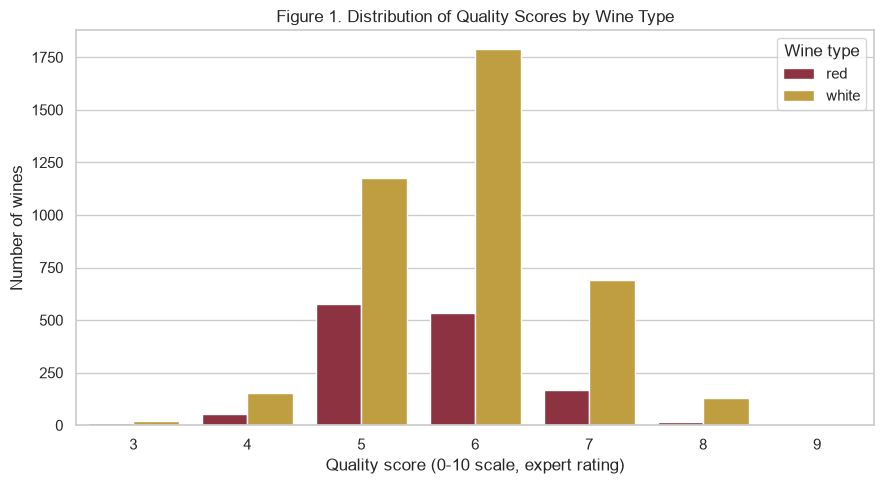

In [47]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(data=df_clean, x="quality", hue="wine_type",
              palette=WINE_PALETTE, ax=ax)
ax.set_title("Figure 1. Distribution of Quality Scores by Wine Type")
ax.set_xlabel("Quality score (0-10 scale, expert rating)")
ax.set_ylabel("Number of wines")
ax.legend(title="Wine type")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig1_quality_distribution.png"), dpi=150)
plt.show()

**Interpretation.** Figure 1 shows that quality scores are concentrated in the middle of the scale, with 5 and 6 the most common scores for both wine types. White wines outnumber red wines at every score, because the white file is about three times larger. Within red wines, 5 is the most common score, while within white wines, 6 is the most common score. The very small bars at 3, 8, and 9 show how few examples exist at the extremes, which limits what can be said about exceptional or poor wines.

### Figure 2: Correlation between physicochemical features and quality

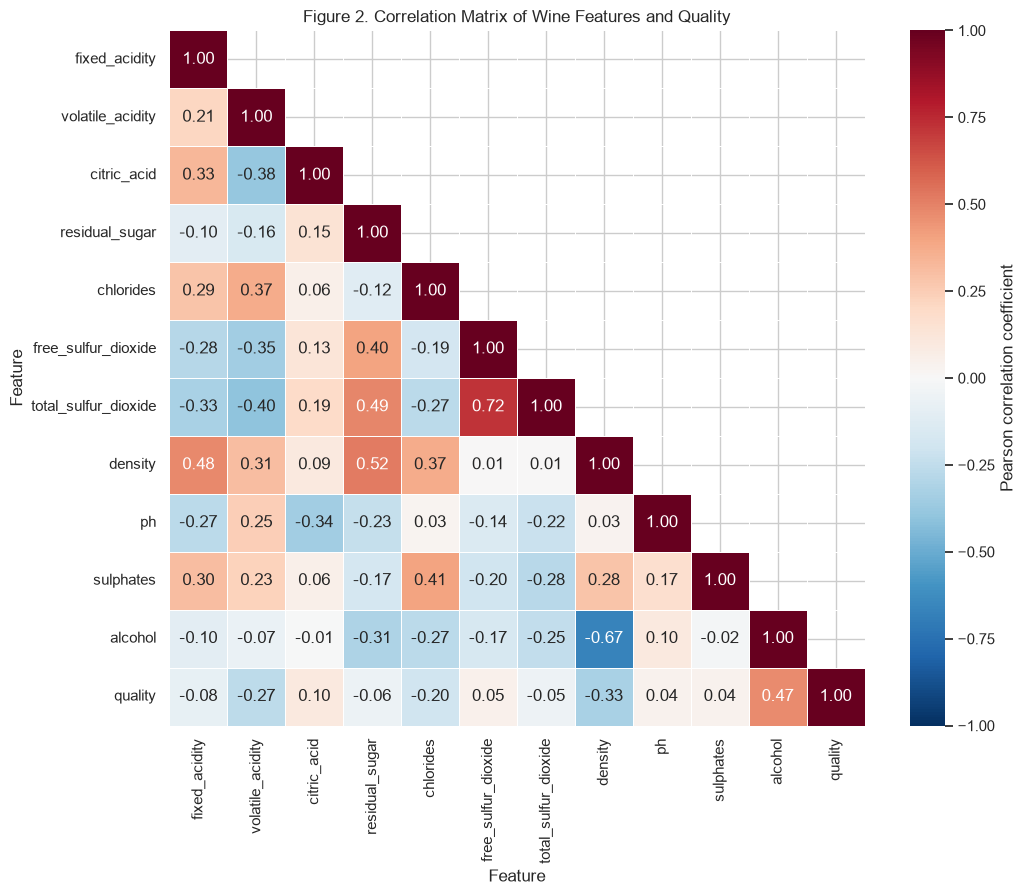

In [48]:
corr = df_clean[FEATURE_COLUMNS + ["quality"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            cbar_kws={"label": "Pearson correlation coefficient"}, ax=ax)
ax.set_title("Figure 2. Correlation Matrix of Wine Features and Quality")
ax.set_xlabel("Feature")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig2_correlation_heatmap.png"), dpi=150)
plt.show()

**Interpretation.** Figure 2 shows the correlation between every pair of features. In the bottom row, alcohol stands out as the feature most associated with higher quality (0.47), and density as the one most associated with lower quality (−0.33). The heatmap also shows strong relationships between features themselves: alcohol and density are strongly negatively correlated (−0.67), because alcohol is lighter than water, and free and total sulfur dioxide are strongly positively correlated (0.72), because free sulfur dioxide is part of the total. This means density's link to quality is likely to be partly a reflection of alcohol content rather than a separate effect.

### Figure 3: Alcohol content across quality scores

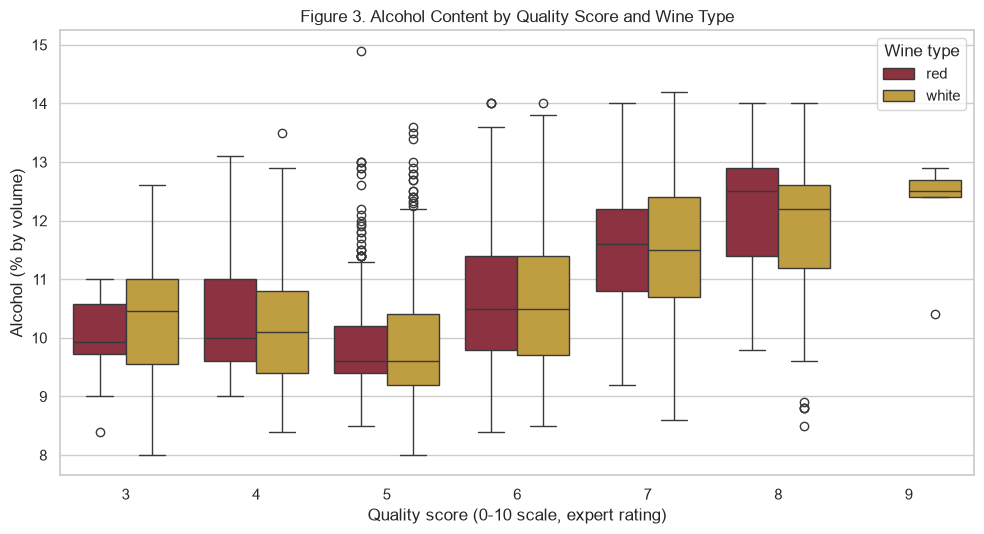

In [49]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df_clean, x="quality", y="alcohol", hue="wine_type",
            palette=WINE_PALETTE, ax=ax)
ax.set_title("Figure 3. Alcohol Content by Quality Score and Wine Type")
ax.set_xlabel("Quality score (0-10 scale, expert rating)")
ax.set_ylabel("Alcohol (% by volume)")
ax.legend(title="Wine type")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig3_alcohol_by_quality.png"), dpi=150)
plt.show()

**Interpretation.** Figure 3 shows the distribution of alcohol content for each quality score. From quality 5 upwards, the median alcohol content rises clearly for both wine types, from about 9.6% at quality 5 to 12.5% for red and 12.2% for white wines at quality 8. The boxes overlap a lot, however: many wines rated 5 have more alcohol than some wines rated 7, so alcohol alone cannot separate quality levels. The pattern is very similar for red and white wines, which agrees with the nearly equal correlations found in the EDA.

### Figure 4: Volatile acidity across quality scores

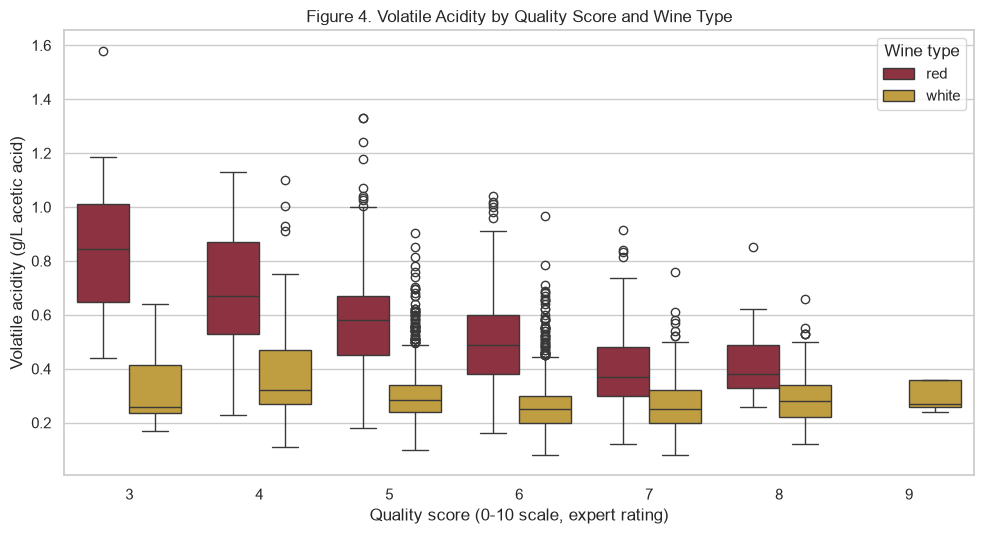

In [50]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df_clean, x="quality", y="volatile_acidity", hue="wine_type",
            palette=WINE_PALETTE, ax=ax)
ax.set_title("Figure 4. Volatile Acidity by Quality Score and Wine Type")
ax.set_xlabel("Quality score (0-10 scale, expert rating)")
ax.set_ylabel("Volatile acidity (g/L acetic acid)")
ax.legend(title="Wine type")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig4_volatile_acidity_by_quality.png"), dpi=150)
plt.show()

**Interpretation.** Figure 4 shows that volatile acidity decreases as quality increases, and that the effect is much stronger in red wines. The median volatile acidity of red wines falls from 0.85 g/L at quality 3 to 0.37 g/L at quality 7, while for white wines it stays between about 0.25 and 0.32 g/L at every quality level. This explains why the correlation between volatile acidity and quality is about twice as strong for red wines (−0.40) as for white wines (−0.19), and it shows why combining the two wine types could hide patterns that only exist in one of them.

## 6. Summary and Interpretation

### What I learned from the dataset
The Wine Quality dataset contains laboratory measurements and expert quality scores for Portuguese *Vinho Verde* wines. After removing 1,177 duplicate rows, 5,320 wines remain: 1,359 red and 3,961 white. The data had no missing values, so the main cleaning work was standardizing column names, removing duplicates, and deciding how to treat outliers. Red and white wines turned out to be chemically very different, so the wine type label added during ingestion was essential for the analysis.

### Patterns and insights
Alcohol content is the feature most strongly associated with quality (r = 0.47), and the pattern is very similar for red and white wines (Figure 3). Higher-quality wines also tend to have lower density, fewer chlorides, and lower volatile acidity (Figure 2). Volatile acidity matters much more for red wines than for white wines (Figure 4), and sulphates and citric acid relate to quality only in red wines. Because many features are correlated with each other, such as alcohol and density (−0.67), some of these relationships probably overlap rather than act independently.

### Limitations and assumptions
- **Quality is a subjective, imbalanced target.** The score is the median rating of expert tasters, not an objective measurement, and 76.6% of wines score 5 or 6 (Figure 1). Conclusions about very good or very poor wines are based on few examples.
- **Duplicates were assumed to be repeated records.** Without a wine ID, some removed rows could be different wines with identical measurements. Removing them changed the average quality only slightly (from 5.82 to 5.80), so this choice does not appear to change the main findings.
- **Outliers were flagged, not removed.** The IQR rule applied to the combined data flags 48.2% of red wines but only 11.1% of white wines, so removing flagged rows would have biased the data against red wines.
- **Limited scope.** All wines come from one Portuguese wine region, and the dataset has no information on grape variety, price, or vintage. The results may not apply to other wines.
- **Correlation is not causation.** This analysis shows associations only. For example, it does not show that adding alcohol would make a wine taste better.

### Surprises and open questions
I expected acidity and sugar to have a strong influence on quality, but alcohol was clearly the strongest single signal, and residual sugar was only weakly related (−0.06). It was also surprising that 18% of the rows were exact duplicates, which is not obvious from a first look at the data. Two open questions remain: whether the duplicates are truly repeated records, and whether outliers should be detected separately for each wine type rather than on the combined data. Both would be worth checking before using this data to train a model.